# House typologies in King County (Seattle area)

**Team 7:** Ugo, Alvaro, Sneha
**Course:** AI Methods I – Day 3: Unsupervised learning (IAAC MaAI 2026/27)

## 0. Introduction and problem definition

**Use case.** An architect, developer or municipality wants to understand which *types of houses* make up the housing stock of King County, for example to plan a retrofit programme or to design a new housing product for the most common type. We look for groups of houses that are similar **as buildings**.

**What defines "similar"?** Only the physical building: size, plot, floors, rooms, basement, build quality, condition and age. We deliberately leave out **price and location**, and use them afterwards to check whether the building types also differ in where they are and what they are worth.

**What makes a group useful?** We can describe it as a house type an architect would recognise, and someone could act on it (e.g. "retrofit the 1950s single-storey houses first").

**Unit of analysis:** one row = one house (21,418 houses sold between May 2014 and May 2015). No aggregation is needed.

In [23]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import umap
from scipy.cluster.hierarchy import linkage, dendrogram

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, adjusted_rand_score

RANDOM_STATE = 42

DATA_DIR = Path("..") / "data"
FIG_DIR = Path("..") / "figures"
MODEL_DIR = Path("..") / "models"
DATASET_DIR = Path("..") / "dataset"
for folder in [FIG_DIR, MODEL_DIR, DATASET_DIR]:
    folder.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)


### 0.1 Load the cleaned data
The cleaned dataset from our Day 1/2 work (18 impossible rows removed). As on Day 2, we keep only the most recent sale of the 177 houses sold twice, so each house appears once.

In [24]:
df = pd.read_csv(DATA_DIR / "housing_clean.csv", dtype={"zipcode": str, "id": str})
df["date"] = pd.to_datetime(df["date"])

# one row per house: keep the most recent sale of houses sold twice
n_before = len(df)
df = df.sort_values("date").drop_duplicates(subset="id", keep="last").reset_index(drop=True)
print(f"{n_before - len(df)} repeat sales removed -> {len(df):,} houses")
df.head()

177 repeat sales removed -> 21,418 houses


,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,4408100095,2014-05-02,308500.0,2,1.00,850,6174,1.0,0,0,4,7,850,0,1950,0,98155,47.7352,-122.328,1100,6174
1,7525100520,2014-05-02,335000.0,2,2.00,1350,2560,1.0,0,0,3,8,1350,0,1976,0,98052,47.6344,-122.107,1790,2560
2,1982201345,2014-05-02,440000.0,2,1.00,800,4850,1.0,0,0,4,7,800,0,1944,0,98107,47.6639,-122.364,1150,4365
3,7525000080,2014-05-02,588500.0,3,1.75,2330,14892,1.0,0,0,3,8,1970,360,1980,0,98074,47.6267,-122.046,2570,14217
4,1737320120,2014-05-02,470000.0,5,2.50,2210,9655,1.0,0,0,3,8,1460,750,1976,0,98011,47.7698,-122.222,2080,8633


## 1. Features and preprocessing

### 1.1 Engineered features
- `age`: years old when sold (sale year − year built).
- `renovated`: 1 if ever renovated (in the raw data `yr_renovated = 0` means "never").
- `has_basement`: 1 if the house has a basement. Most houses have 0 sqft of basement, so a yes/no flag describes it better than the area.
- `sqft_per_bedroom`: how generous the rooms are.
- `floor_area_ratio`: living area ÷ plot area, i.e. how much of the plot the house "uses" (dense vs spacious).

**Skewed columns:** living area and lot size are strongly right-skewed (a few huge plots). Without a transform, those few houses would dominate the distances, so we take `log10`.

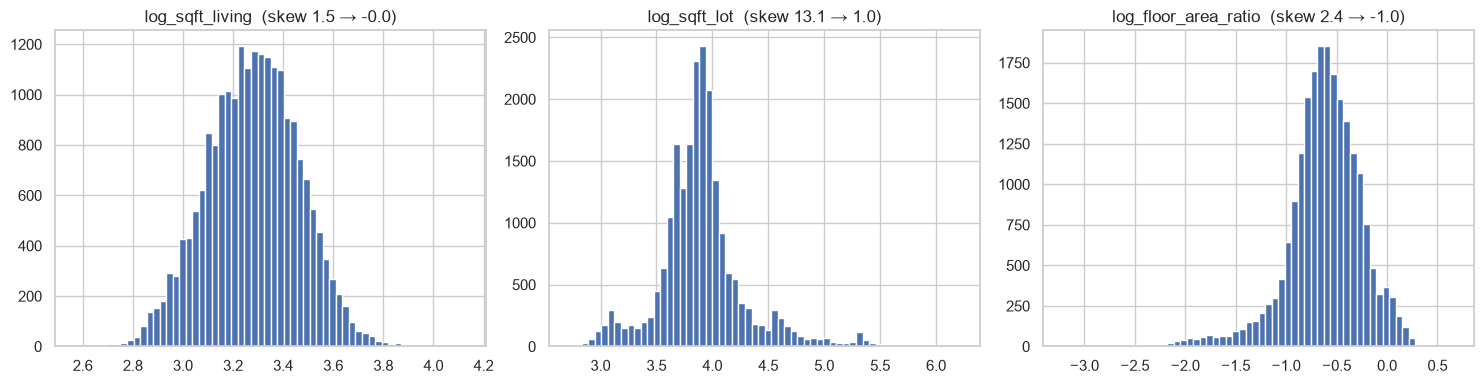

In [25]:
df["age"] = df["date"].dt.year - df["yr_built"]                  # years old when sold
df["renovated"] = (df["yr_renovated"] > 0).astype(int)           # 0 in the raw data means "never"
df["has_basement"] = (df["sqft_basement"] > 0).astype(int)
df["sqft_per_bedroom"] = df["sqft_living"] / df["bedrooms"]
df["floor_area_ratio"] = df["sqft_living"] / df["sqft_lot"]      # how much of the plot the house "uses"

# log10 of the skewed size columns
df["log_sqft_living"] = np.log10(df["sqft_living"])
df["log_sqft_lot"] = np.log10(df["sqft_lot"])
df["log_floor_area_ratio"] = np.log10(df["floor_area_ratio"])

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (raw, logged) in zip(axes, [("sqft_living", "log_sqft_living"), ("sqft_lot", "log_sqft_lot"),
                                    ("floor_area_ratio", "log_floor_area_ratio")]):
    ax.hist(df[logged], bins=60)
    ax.set_title(f"{logged}  (skew {df[raw].skew():.1f} → {df[logged].skew():.1f})")
plt.tight_layout()
plt.show()

### 1.2 Features we cluster on, and features kept aside

| Cluster on (the building) | Kept aside (for interpretation) |
|---|---|
| `log_sqft_living`, `log_sqft_lot` | `price`: is a type worth more? |
| `floors`, `bedrooms`, `bathrooms`, `has_basement` | `lat`, `long`, `zipcode`: where is each type? |
| `grade` (build quality), `condition` (upkeep), `age` | `waterfront`, `view`, `renovated`, `sqft_living15` |

**Why these:** choosing the columns chooses the meaning of the clusters. With price or location as inputs we would find *markets* or *neighbourhoods*; we want *building types*, so we keep only properties of the building and use price and location to test our names afterwards.

**Left out on purpose:**
- `log_floor_area_ratio`: it is exactly `log_sqft_living − log_sqft_lot`, so it adds no information and would count size and plot twice.
- `renovated`: only 4 % of houses. A rare yes/no flag tends to create a cluster of its own ("the renovated ones"), which is not a building type.
- `sqft_above`: equal to living area minus basement.

In [26]:
CLUSTER_FEATURES = [
    "log_sqft_living", "log_sqft_lot",                           # size and plot
    "floors", "bedrooms", "bathrooms", "has_basement",           # layout
    "grade", "condition", "age",                                 # quality and age
]
KEPT_ASIDE = ["price", "lat", "long", "zipcode", "waterfront", "view", "renovated", "sqft_living15"]

X = df[CLUSTER_FEATURES]
X.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
log_sqft_living,21418.0,3.28,0.18,2.57,3.16,3.28,3.41,4.13
log_sqft_lot,21418.0,3.90,0.39,2.72,3.70,3.88,4.03,6.22
floors,21418.0,1.50,0.54,1.00,1.00,1.50,2.00,3.50
bedrooms,21418.0,3.37,0.90,1.00,3.00,3.00,4.00,10.00
bathrooms,21418.0,2.12,0.77,0.50,1.75,2.25,2.50,8.00
has_basement,21418.0,0.39,0.49,0.00,0.00,0.00,1.00,1.00
grade,21418.0,7.66,1.17,3.00,7.00,7.00,8.00,13.00
condition,21418.0,3.41,0.65,1.00,3.00,3.00,4.00,5.00
age,21418.0,43.23,29.39,-1.00,17.00,39.00,63.00,115.00


### 1.3 Scaling
The features have very different units (years, counts, a 1–13 grade, log of square feet). K-Means uses distances, so without scaling `age` (0–115) would dominate `floors` (1–3.5). `StandardScaler` gives every feature mean 0 and standard deviation 1, so each one counts equally. For the final model, the scaler sits inside a `Pipeline` with K-Means (section 3).

In [27]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("mean ≈ 0:", X_scaled.mean(axis=0).round(2))
print("std  = 1:", X_scaled.std(axis=0).round(2))

mean ≈ 0: [ 0.  0.  0.  0. -0. -0. -0. -0. -0.]
std  = 1: [1. 1. 1. 1. 1. 1. 1. 1. 1.]


## 2. Dimensionality reduction

### 2.1 PCA: how many real dimensions?
PC1 explains 39 % of the variance, PC2 19 %, PC3 12 %. You need 4 components to reach 80 %, so the houses differ along several independent directions, not just one "size" axis.

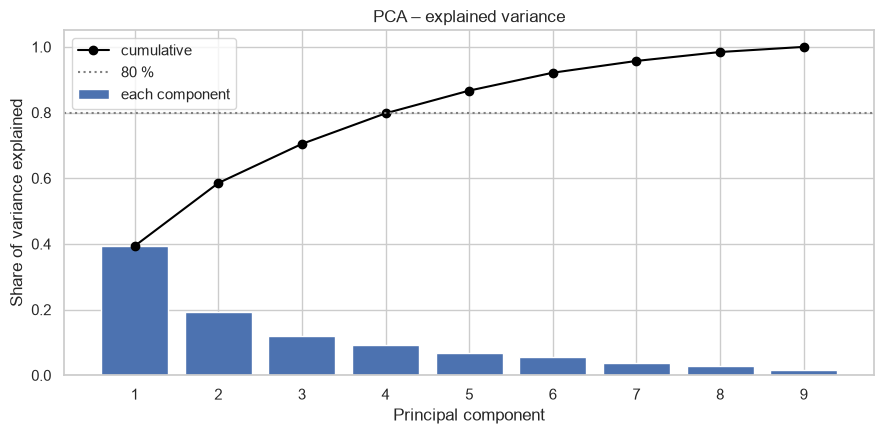

     explained  cumulative
PC1      0.394       0.394
PC2      0.192       0.585
PC3      0.119       0.705
PC4      0.093       0.798
PC5      0.069       0.867
PC6      0.054       0.921
PC7      0.036       0.957
PC8      0.027       0.984
PC9      0.016       1.000


In [28]:
pca_full = PCA(random_state=RANDOM_STATE).fit(X_scaled)
evr = pca_full.explained_variance_ratio_

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(range(1, len(evr) + 1), evr, label="each component")
ax.plot(range(1, len(evr) + 1), np.cumsum(evr), "o-", color="black", label="cumulative")
ax.axhline(0.8, ls=":", color="grey", label="80 %")
ax.set_xticks(range(1, len(evr) + 1))
ax.set_xlabel("Principal component")
ax.set_ylabel("Share of variance explained")
ax.set_title("PCA – explained variance")
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "01_pca_explained_variance.png", dpi=150, bbox_inches="tight")
plt.show()

print(pd.DataFrame({"explained": evr, "cumulative": np.cumsum(evr)},
                   index=[f"PC{i}" for i in range(1, len(evr) + 1)]).round(3))

### 2.2 Reading the loadings
<!-- Check these against your heatmap and edit: -->
- **PC1 ≈ "big, new, high-quality house":** living area, bathrooms, grade and floors load positively, age negatively.
- **PC2 ≈ "plot size":** mostly the lot size, i.e. spacious suburban/rural plots vs compact city plots.
- **PC3 ≈ "older house with a basement in good condition":** basement, condition and age load together. This is the classic mid-century Seattle house.

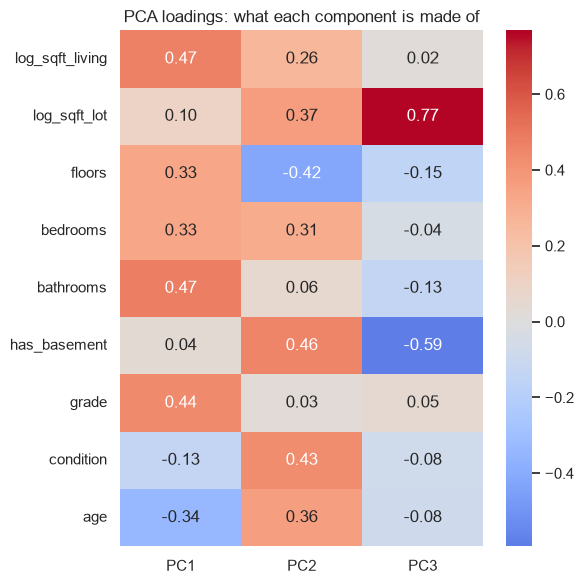

In [29]:
loadings = pd.DataFrame(pca_full.components_[:3].T, index=CLUSTER_FEATURES, columns=["PC1", "PC2", "PC3"])

fig, ax = plt.subplots(figsize=(6, 6))
sns.heatmap(loadings, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("PCA loadings: what each component is made of")
plt.tight_layout()
plt.savefig(FIG_DIR / "02_pca_loadings.png", dpi=150, bbox_inches="tight")
plt.show()

### 2.3 PCA and UMAP maps
PCA is a linear projection: its axes have a meaning (the loadings above). UMAP (`n_neighbors=30`, `min_dist=0.1`) is non-linear: it keeps houses that are similar close together. **Careful:** in UMAP, the size of the blobs and the distances between them mean nothing. Only "who is next to whom" can be read. We keep both 2D coordinates for the dataset.

/opt/homebrew/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


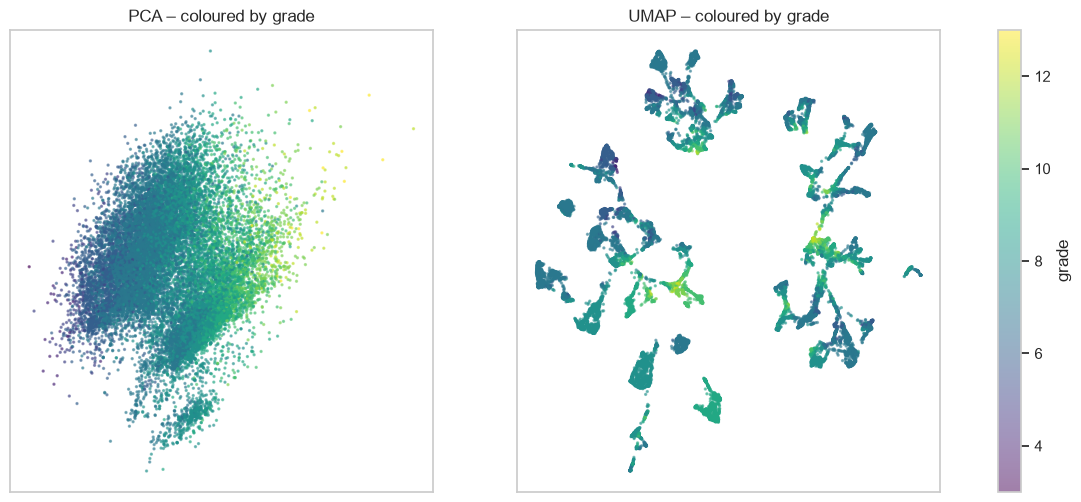

In [30]:
pca_2d = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(X_scaled)
df["pca_x"], df["pca_y"] = pca_2d[:, 0], pca_2d[:, 1]

reducer = umap.UMAP(n_neighbors=30, min_dist=0.1, random_state=RANDOM_STATE)
umap_2d = reducer.fit_transform(X_scaled)          # takes about a minute
df["umap_x"], df["umap_y"] = umap_2d[:, 0], umap_2d[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, (x, y, title) in zip(axes, [("pca_x", "pca_y", "PCA"), ("umap_x", "umap_y", "UMAP")]):
    sc = ax.scatter(df[x], df[y], c=df["grade"], cmap="viridis", s=2, alpha=0.5)
    ax.set_title(f"{title} – coloured by grade")
    ax.set_xticks([]); ax.set_yticks([])
fig.colorbar(sc, ax=axes, label="grade")
plt.savefig(FIG_DIR / "03_pca_umap_maps.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. Clustering

### 3.1 K-Means: choosing k
We try k = 2 to 10. The elbow plot shows the within-cluster spread (it always falls; we look for a bend). The silhouette measures how well separated the clusters are (−1 to 1).

**Honest reading:** the silhouette is low and flat (0.21–0.26 for every k) and the elbow has no sharp bend. House types form a **continuum**, not separate islands. There is no "true" k, so we choose it for **stability and interpretability**:
- k = 4 gives the same clusters for every random seed (section 4), and each group can be described as a recognisable house type.
- k = 5 was unstable: different seeds gave different groups (agreement only 0.59).
- k = 6 adds an interesting small "urban townhouse" group (tiny plots), but is less stable.

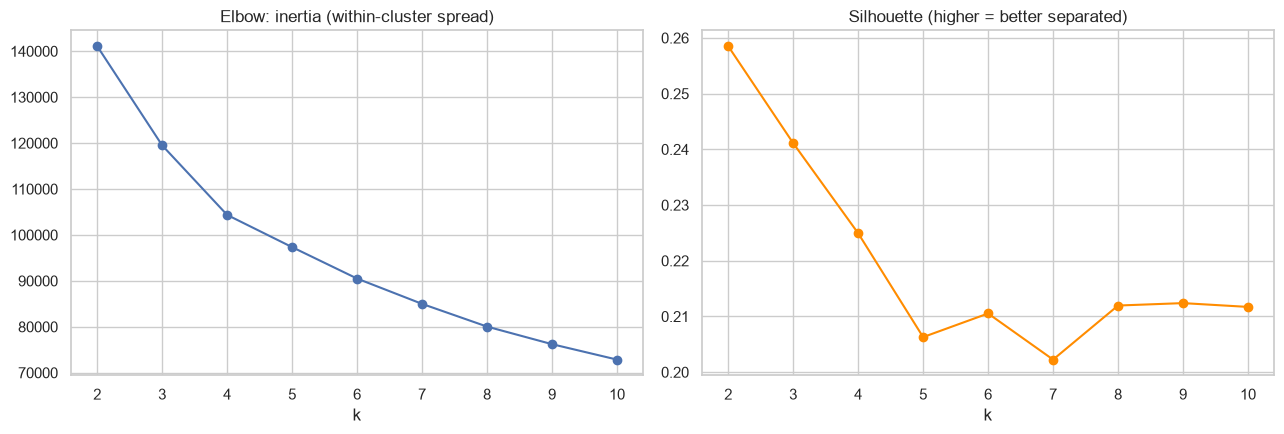

,k,inertia,silhouette
0,2,141103.003,0.259
1,3,119499.941,0.241
2,4,104353.809,0.225
3,5,97339.385,0.206
4,6,90497.161,0.211
5,7,84987.126,0.202
6,8,80041.585,0.212
7,9,76212.641,0.212
8,10,72856.464,0.212


In [31]:
ks = range(2, 11)
rng = np.random.default_rng(RANDOM_STATE)
sample_idx = rng.choice(len(X_scaled), 5000, replace=False)   # silhouette on a sample: faster

inertias, silhouettes = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_scaled[sample_idx], km.labels_[sample_idx]))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(list(ks), inertias, "o-")
axes[0].set_title("Elbow: inertia (within-cluster spread)")
axes[0].set_xlabel("k")
axes[1].plot(list(ks), silhouettes, "o-", color="darkorange")
axes[1].set_title("Silhouette (higher = better separated)")
axes[1].set_xlabel("k")
plt.tight_layout()
plt.savefig(FIG_DIR / "04_choice_of_k.png", dpi=150, bbox_inches="tight")
plt.show()

pd.DataFrame({"k": list(ks), "inertia": inertias, "silhouette": silhouettes}).round(3)

### 3.2 The final K-Means model (k = 4)
Scaler and K-Means together in one `Pipeline`, so the saved model takes the raw feature columns.

In [32]:
K = 4   # stable and nameable; the silhouette is flat (see above)

kmeans_pipe = Pipeline([
    ("scale", StandardScaler()),
    ("kmeans", KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE)),
])
kmeans_pipe.fit(X)
df["cluster"] = kmeans_pipe.predict(X)

print(df["cluster"].value_counts().sort_index())
print("silhouette (sample):", round(silhouette_score(X_scaled[sample_idx], df["cluster"].values[sample_idx]), 3))

cluster
0    6095
1    6388
2    4080
3    4855
Name: count, dtype: int64
silhouette (sample): 0.225


### 3.3 Second algorithm: hierarchical clustering (Ward)
Ward merges the two most similar groups step by step. On all 21,418 houses this is slow, so we use the same random sample of 5,000 houses. We cut the tree at 4 clusters and compare with K-Means using the **adjusted Rand index** (ARI: 1 = identical groups, 0 = no better than chance).

**Result:** ARI = 0.63, so the methods partly agree. The cross-table shows that three groups match almost one-to-one, while Ward splits K-Means' "large new" houses differently. Ward and K-Means both look for compact, round-ish groups, which suits a continuum like this. A density method like DBSCAN would likely find one big blob.

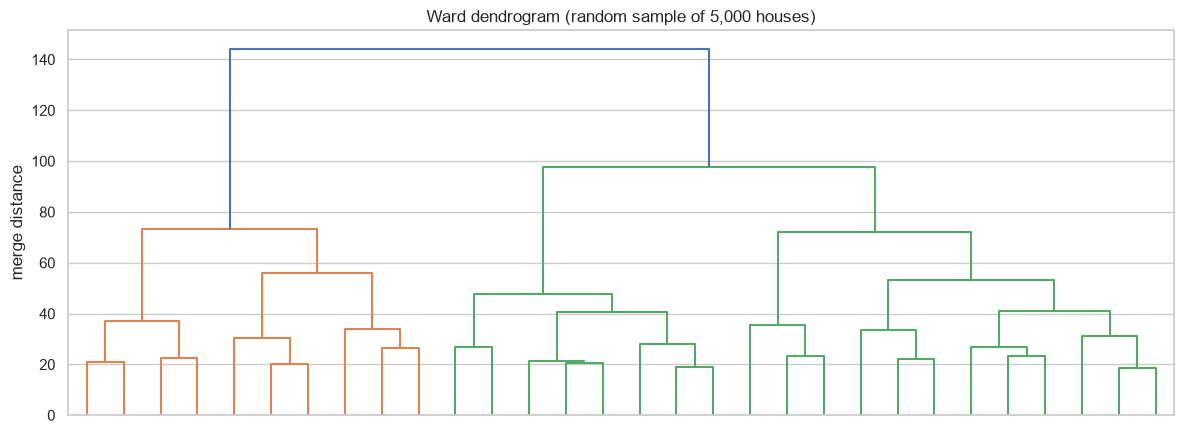

Agreement K-Means vs Ward (ARI): 0.63


Ward,0,1,2,3
K-Means,,,,
0,1358,10,54,6
1,255,9,1214,0
2,207,166,12,553
3,11,1063,45,37


In [33]:
X_sample = X_scaled[sample_idx]

Z = linkage(X_sample, method="ward")
fig, ax = plt.subplots(figsize=(12, 4.5))
dendrogram(Z, truncate_mode="lastp", p=30, no_labels=True, ax=ax)
ax.set_title("Ward dendrogram (random sample of 5,000 houses)")
ax.set_ylabel("merge distance")
plt.tight_layout()
plt.savefig(FIG_DIR / "05_dendrogram.png", dpi=150, bbox_inches="tight")
plt.show()

ward_labels = AgglomerativeClustering(n_clusters=K, linkage="ward").fit_predict(X_sample)
ari_methods = adjusted_rand_score(df["cluster"].values[sample_idx], ward_labels)
print(f"Agreement K-Means vs Ward (ARI): {ari_methods:.2f}")

pd.crosstab(df["cluster"].values[sample_idx], ward_labels, rownames=["K-Means"], colnames=["Ward"])

## 4. Stability
Are the clusters an accident of one random start, or of the particular houses in the data? We re-run K-Means:
- with 5 other random seeds;
- on 5 random subsamples of 80 % of the houses.

Each time we compare with our clusters using the ARI.

**Result:** mean ARI 0.997 across seeds and 0.993 across subsamples. The 4 groups are very stable, even though the silhouette is low: the borders between types are fuzzy, but the same types come back every time.

In [34]:
seed_aris = []
for seed in [0, 1, 2, 3, 4]:
    labels_seed = KMeans(n_clusters=K, n_init=10, random_state=seed).fit_predict(X_scaled)
    seed_aris.append(adjusted_rand_score(df["cluster"], labels_seed))

sub_aris = []
for i in range(5):
    idx = rng.choice(len(X_scaled), int(0.8 * len(X_scaled)), replace=False)
    km_sub = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE).fit(X_scaled[idx])
    sub_aris.append(adjusted_rand_score(df["cluster"], km_sub.predict(X_scaled)))

print("ARI, other random seeds:  ", np.round(seed_aris, 3), "mean", round(np.mean(seed_aris), 3))
print("ARI, 80 % subsamples:     ", np.round(sub_aris, 3), "mean", round(np.mean(sub_aris), 3))

ARI, other random seeds:   [0.996 0.993 0.999 0.999 0.999] mean 0.997
ARI, 80 % subsamples:      [0.995 0.994 0.992 0.994 0.99 ] mean 0.993


## 5. Interpretation

### 5.1 Profiles: what does each cluster look like?
Median values of the features we clustered on, plus the share of the data.

In [35]:
profile = df.groupby("cluster").agg(
    houses=("price", "size"),
    sqft_living=("sqft_living", "median"),
    sqft_lot=("sqft_lot", "median"),
    floors=("floors", "median"),
    bedrooms=("bedrooms", "median"),
    bathrooms=("bathrooms", "median"),
    basement_share=("has_basement", "mean"),
    grade=("grade", "median"),
    condition=("condition", "median"),
    age=("age", "median"),
)
profile["share_%"] = (100 * profile["houses"] / len(df)).round(1)
profile.round(2)

,houses,sqft_living,sqft_lot,floors,bedrooms,bathrooms,basement_share,grade,condition,age,share_%
cluster,,,,,,,,,,,
0,6095,2100.0,8118.0,1.0,4.0,2.00,0.93,7.0,4.0,53.0,28.5
1,6388,1260.0,7620.0,1.0,3.0,1.00,0.11,7.0,3.0,62.0,29.8
2,4080,3190.0,11445.0,2.0,4.0,2.75,0.31,9.0,3.0,19.0,19.0
3,4855,1910.0,4725.0,2.0,3.0,2.50,0.17,8.0,3.0,11.0,22.7


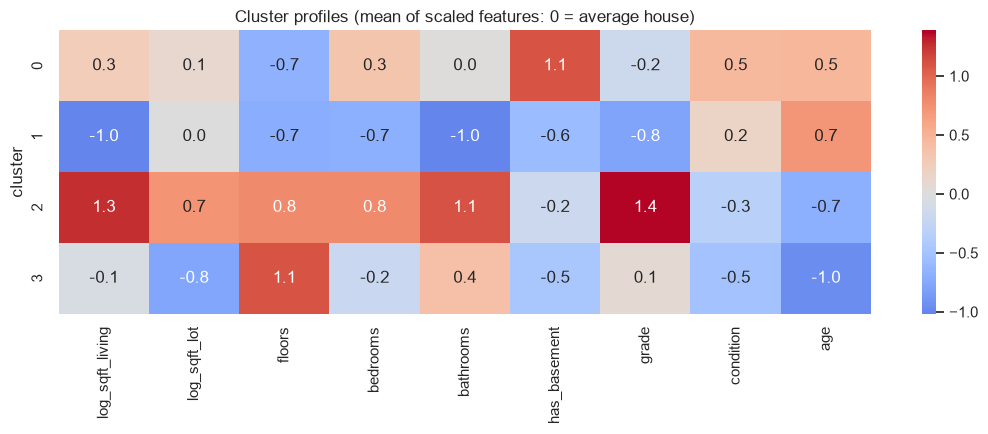

In [36]:
z_profile = pd.DataFrame(X_scaled, columns=CLUSTER_FEATURES).groupby(df["cluster"]).mean()

fig, ax = plt.subplots(figsize=(11, 4.5))
sns.heatmap(z_profile, annot=True, fmt=".1f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Cluster profiles (mean of scaled features: 0 = average house)")
plt.tight_layout()
plt.savefig(FIG_DIR / "06_cluster_profiles.png", dpi=150, bbox_inches="tight")
plt.show()

### 5.2 Cross-checks with variables we did NOT cluster on
Price, location, waterfront, view and renovation were not used to build the groups. If the building types also differ in these, the groups are meaningful beyond the features we chose.

In [37]:
aside = df.groupby("cluster").agg(
    median_price=("price", "median"),
    price_per_sqft=("price", lambda p: (p / df.loc[p.index, "sqft_living"]).median()),
    waterfront_share=("waterfront", "mean"),
    good_view_share=("view", lambda v: (v >= 2).mean()),
    renovated_share=("renovated", "mean"),
    median_lat=("lat", "median"),
    median_long=("long", "median"),
)
aside.round(3)

,median_price,price_per_sqft,waterfront_share,good_view_share,renovated_share,median_lat,median_long
cluster,,,,,,,
0,497300.0,236.318,0.008,0.116,0.055,47.594,-122.282
1,334000.0,270.797,0.004,0.037,0.047,47.553,-122.290
2,770500.0,244.669,0.019,0.168,0.050,47.588,-122.131
3,415000.0,227.273,0.002,0.032,0.014,47.552,-122.190


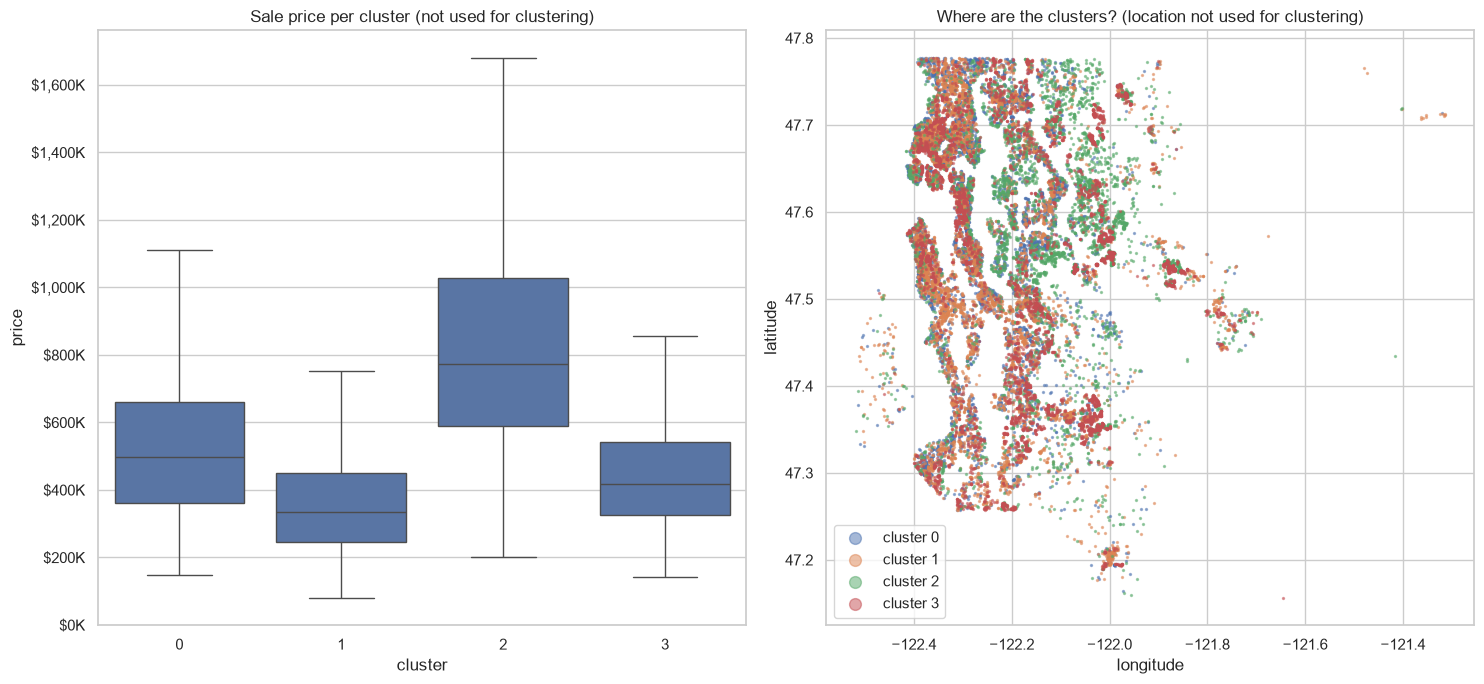

0 {'98115': 252, '98034': 217, '98117': 202, '98023': 189, '98006': 176}
1 {'98118': 232, '98117': 228, '98133': 221, '98155': 218, '98103': 217}
2 {'98075': 245, '98074': 235, '98006': 212, '98052': 182, '98053': 173}
3 {'98038': 332, '98029': 210, '98103': 196, '98042': 193, '98065': 169}


In [38]:
fig, axes = plt.subplots(1, 2, figsize=(15, 7))
sns.boxplot(data=df, x="cluster", y="price", ax=axes[0], showfliers=False)
axes[0].set_title("Sale price per cluster (not used for clustering)")
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"${v/1000:,.0f}K"))

for c, rows in df.groupby("cluster"):
    axes[1].scatter(rows["long"], rows["lat"], s=2, alpha=0.5, label=f"cluster {c}")
axes[1].set_title("Where are the clusters? (location not used for clustering)")
axes[1].set_xlabel("longitude"); axes[1].set_ylabel("latitude")
axes[1].legend(markerscale=6)
plt.tight_layout()
plt.savefig(FIG_DIR / "07_clusters_price_and_map.png", dpi=150, bbox_inches="tight")
plt.show()

# top zipcodes per cluster
for c, rows in df.groupby("cluster"):
    print(c, rows["zipcode"].value_counts().head(5).to_dict())

### 5.3 Naming the clusters
<!-- These are suggestions from our run. Check the cluster numbers against YOUR profile table before using them, and rewrite in your own words. -->

| Cluster | Name | Share | Why this name |
|---|---|---|---|
| 1 | **Post-war single-storey bungalows** | 29.8 % | Smallest (1,260 sqft), 1 floor, 1 bathroom, median 62 years old, rarely a basement. Cheapest ($334K) but the highest price per sqft ($271): small houses in central Seattle (zipcodes 98118, 98117, 98133). |
| 0 | **Mid-century houses with basements** | 28.5 % | 93 % have a basement, 1 floor above ground, ~2,100 sqft, median 53 years old, the best condition (4). Same inner-Seattle zipcodes as the bungalows (98115, 98117), slightly more often with a view. $497K. |
| 3 | **New compact two-storey family homes** | 22.7 % | Newest (11 years), 2 floors, 2.5 bathrooms, the smallest plots (4,725 sqft): suburban developments in the south and east (98038, 98029, 98042). $415K, the lowest price per sqft. |
| 2 | **Large premium suburban homes** | 19.0 % | Biggest (3,190 sqft) on large plots (11,445 sqft), grade 9, 2 floors, ~19 years old. On the Eastside (Sammamish, Bellevue, Redmond: 98075, 98074, 98006). Most expensive ($771K), most often with a view or on the water. |

**Reading:** the clusters split cleanly by **age and place**: the two older types are in Seattle itself, the two newer types in the suburbs. Location was never used to build them. Price follows build quality and size more than the type itself: the bungalows are cheapest overall but cost the most per square foot, because of where they are.

In [39]:
CLUSTER_NAMES = {
    0: "mid-century houses with basements",
    1: "post-war single-storey bungalows",
    2: "large premium suburban homes",
    3: "new compact two-storey family homes",
}
df["cluster_name"] = df["cluster"].map(CLUSTER_NAMES)

summary = profile[["houses", "share_%", "sqft_living", "sqft_lot", "floors", "grade", "age"]].join(
    aside[["median_price"]])
summary.insert(0, "name", summary.index.map(CLUSTER_NAMES))
summary

,name,houses,share_%,sqft_living,sqft_lot,floors,grade,age,median_price
cluster,,,,,,,,,
0,mid-century houses with basements,6095,28.5,2100.0,8118.0,1.0,7.0,53.0,497300.0
1,post-war single-storey bungalows,6388,29.8,1260.0,7620.0,1.0,7.0,62.0,334000.0
2,large premium suburban homes,4080,19.0,3190.0,11445.0,2.0,9.0,19.0,770500.0
3,new compact two-storey family homes,4855,22.7,1910.0,4725.0,2.0,8.0,11.0,415000.0


### 5.4 The named clusters on the PCA and UMAP maps
On PCA, the groups lie side by side along PC1 (size/quality/age) and overlap at the borders: a continuum, as the low silhouette said.

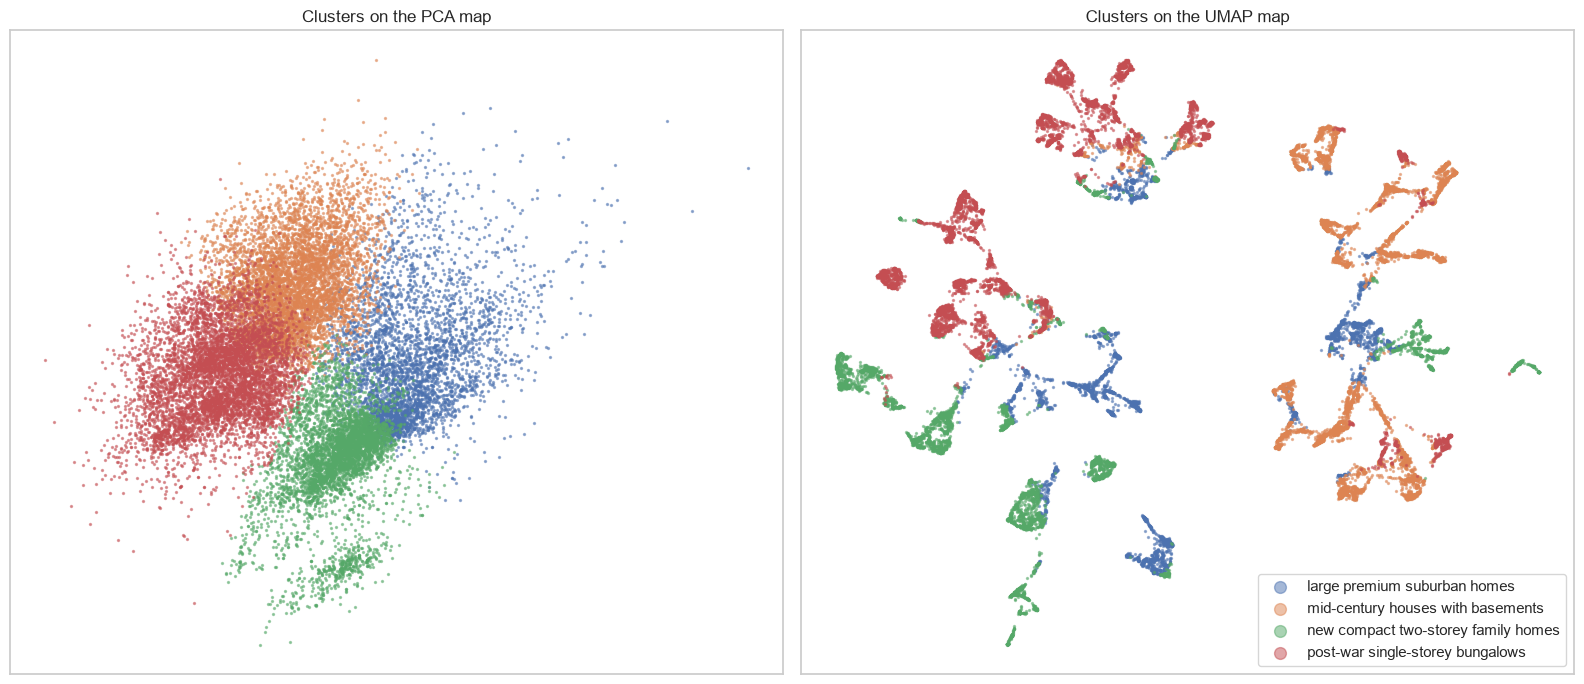

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, (x, y, title) in zip(axes, [("pca_x", "pca_y", "PCA"), ("umap_x", "umap_y", "UMAP")]):
    for name, rows in df.groupby("cluster_name"):
        ax.scatter(rows[x], rows[y], s=2, alpha=0.5, label=name)
    ax.set_title(f"Clusters on the {title} map")
    ax.set_xticks([]); ax.set_yticks([])
axes[1].legend(markerscale=6, loc="best")
plt.tight_layout()
plt.savefig(FIG_DIR / "08_clusters_on_maps.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Save and reuse the model
We save the whole pipeline (scaler + K-Means). K-Means has `.predict()`, so it can assign new houses directly; no extra "assigner" model is needed. A new house needs the 9 feature columns, including the log-transformed sizes.

**Example:** a new 1,800 sqft, two-storey, grade-8 house on a 4,000 sqft plot, 5 years old.

In [41]:
model_path = MODEL_DIR / "model.joblib"
joblib.dump(kmeans_pipe, model_path)
print("saved", model_path)

loaded = joblib.load(model_path)

new_house = pd.DataFrame([{
    "sqft_living": 1800, "sqft_lot": 4000, "floors": 2, "bedrooms": 3, "bathrooms": 2.5,
    "has_basement": 0, "grade": 8, "condition": 3, "age": 5,
}])
new_house["log_sqft_living"] = np.log10(new_house["sqft_living"])
new_house["log_sqft_lot"] = np.log10(new_house["sqft_lot"])

c = loaded.predict(new_house[CLUSTER_FEATURES])[0]
print(f"This new house belongs to cluster {c}: {CLUSTER_NAMES[c]}")

saved ../models/model.joblib
This new house belongs to cluster 3: new compact two-storey family homes


## 7. Export the clustered dataset (the main deliverable)
The final table contains:
- the cleaned data;
- our engineered features;
- `cluster` and `cluster_name`;
- the PCA and UMAP coordinates.

We **drop `id`**: combined with the exact location it identifies individual properties, and nobody needs it to reuse the data.

(21418, 34) -> ../dataset/king_county_house_typologies.csv


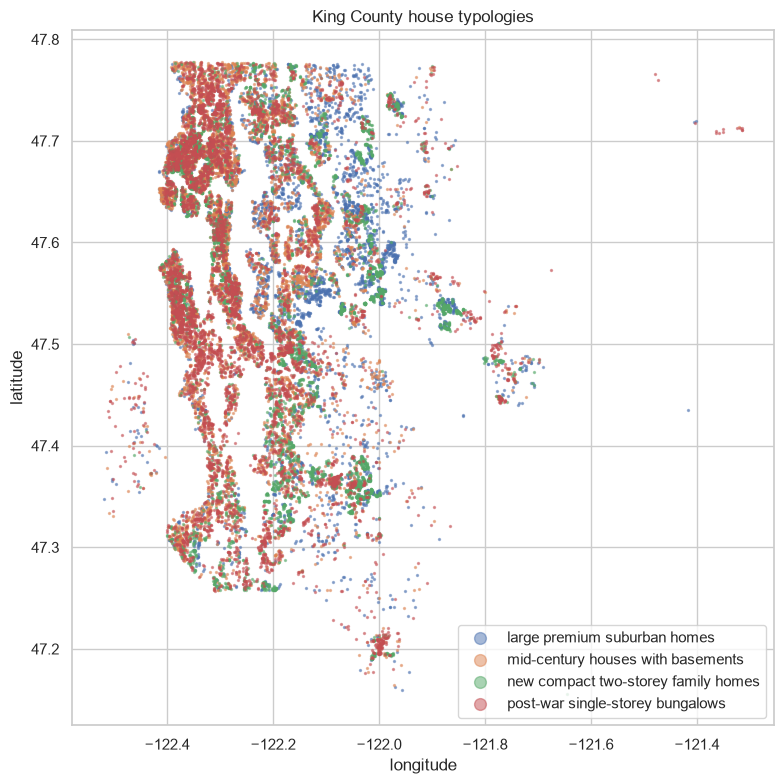

,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,...,sqft_lot15,age,renovated,has_basement,sqft_per_bedroom,floor_area_ratio,log_sqft_living,log_sqft_lot,log_floor_area_ratio,cluster,cluster_name,pca_x,pca_y,umap_x,umap_y
0,2014-05-02,308500.0,2,1.00,850,6174,1.0,0,0,4,7,850,0,1950,0,...,6174,64,0,0,425.000000,0.137674,2.929419,3.790567,-0.861148,1,post-war single-storey bungalows,-3.056737,-0.506819,-0.266878,14.190488
1,2014-05-02,335000.0,2,2.00,1350,2560,1.0,0,0,3,8,1350,0,1976,0,...,2560,38,0,0,675.000000,0.527344,3.130334,3.408240,-0.277906,1,post-war single-storey bungalows,-1.147419,-1.467588,-5.365628,10.796024
2,2014-05-02,440000.0,2,1.00,800,4850,1.0,0,0,4,7,800,0,1944,0,...,4365,70,0,0,400.000000,0.164948,2.903090,3.685742,-0.782652,1,post-war single-storey bungalows,-3.218904,-0.568332,-0.317697,14.188598
3,2014-05-02,588500.0,3,1.75,2330,14892,1.0,0,0,3,8,1970,360,1980,0,...,14217,34,0,1,776.666667,0.156460,3.367356,4.172953,-0.805597,0,mid-century houses with basements,-0.009956,0.789343,11.929801,-1.029598
4,2014-05-02,470000.0,5,2.50,2210,9655,1.0,0,0,3,8,1460,750,1976,0,...,8633,38,0,1,442.000000,0.228897,3.344392,3.984752,-0.640360,0,mid-century houses with basements,1.038375,1.375512,9.409318,3.124751


In [42]:
EXPORT_COLUMNS = (
    ["date", "price", "bedrooms", "bathrooms", "sqft_living", "sqft_lot", "floors", "waterfront", "view",
     "condition", "grade", "sqft_above", "sqft_basement", "yr_built", "yr_renovated", "zipcode",
     "lat", "long", "sqft_living15", "sqft_lot15"]                                  # cleaned data (id dropped)
    + ["age", "renovated", "has_basement", "sqft_per_bedroom", "floor_area_ratio",
       "log_sqft_living", "log_sqft_lot", "log_floor_area_ratio"]                   # engineered features
    + ["cluster", "cluster_name", "pca_x", "pca_y", "umap_x", "umap_y"]             # results
)
final = df[EXPORT_COLUMNS].copy()
final["date"] = final["date"].dt.date

dataset_path = DATASET_DIR / "king_county_house_typologies.csv"
final.to_csv(dataset_path, index=False)
print(final.shape, "->", dataset_path)

# figure for the dataset card
fig, ax = plt.subplots(figsize=(8, 8))
for name, rows in final.groupby("cluster_name"):
    ax.scatter(rows["long"], rows["lat"], s=2, alpha=0.5, label=name)
ax.set_title("King County house typologies")
ax.set_xlabel("longitude"); ax.set_ylabel("latitude")
ax.legend(markerscale=6)
plt.tight_layout()
plt.savefig(DATASET_DIR / "clusters_map.png", dpi=150, bbox_inches="tight")
plt.show()

final.head()

## 8. Conclusions

### Key findings
- The 21,418 houses form **4 stable house types**:
  - post-war bungalows (30 %);
  - mid-century houses with basements (29 %);
  - new compact two-storey homes (23 %);
  - large premium suburban homes (19 %).
- The types are **very stable** (ARI 0.99 across seeds and subsamples) but **not sharply separated** (silhouette 0.23): house types are a continuum with fuzzy borders.
- K-Means and Ward partly agree (ARI 0.63).
- **Without using location**, the types separate by place: the two older types are in Seattle, the two newer ones in the suburbs. Building age and urban development are tightly linked.
- **Price** rises from bungalows ($334K) to premium homes ($771K), but the bungalows have the highest price per sqft ($271): location, not the building, drives their value.

### Limitations and biases
- **Data:** only houses sold in 2014–15 in one US county. Houses that didn't sell, apartments and commercial buildings are missing, so the types describe the market, not the whole building stock.
- **Choices:** other features or another k give other groups. These 4 types are one reasonable reading, not the truth. At k = 6 a small "urban townhouse" group appears.
- **Weak separation:** many houses sit between two types. Their label is less meaningful than the label of a typical house.
- **Do not use** the clusters for other regions, to value a house, or to judge an individual property: they describe types, not quality.